# Molecular dynamics
*A Lennard-Jones liquid: neighbour cells from sorted keys, forces from the energy, and the energy kept*

Argon-like atoms interact through one pair energy, the Lennard-Jones potential. This page writes only that energy, gets every force from its gradient in reverse mode, finds each atom's neighbours with a cell list built from sorted keys, and runs the atoms forward with velocity Verlet. It checks the forces against a brute-force sum, the energy drift against the step size, and the liquid's structure and energy against a published reference state point.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/anim.py",
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, plot_style, show, to_numpy, xp
plot_style()

## The liquid, once

Reduced units: lengths in `sigma`, energies in `epsilon`, mass 1, so time is in `sigma sqrt(m / epsilon)` and temperature in `epsilon / k_B`. Two atoms at distance `r` have energy `u(r) = 4 (r^-12 - r^-6)`. The page uses the state point `T = 0.85`, `rho = 0.776` atoms per `sigma^3`, a liquid near coexistence, in a cubic box with periodic faces, so an atom sees the nearest periodic image of every other.

- The pair energy is cut off at `rc = 2.5` and smoothed so that both the energy and the force go to zero there (the shifted-force form `u(r) - u(rc) - u'(rc) (r - rc)`), which keeps the total energy conserved when a pair crosses the cutoff.
- The model leaves out long-range tails (they are added back, for the comparison with the reference, as the standard correction), electrostatics, molecular shape and any thermostat during the production run: it is the microcanonical liquid.
- Reading the system at a time takes the box, the atoms' positions `r` and their velocities.

Declare the words once as a `KernelKind`. One lane is one atom, and its `r` is its position.

In [3]:
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Index, Kernel, Mutable, Param, Scalar, Sorted, Table, Vector
from hawk.diff import vjp
from hawk.ext import DATA_ONLY, KernelKind

RHO, TEMPERATURE, RC = 0.776, 0.85, 2.5
U_RC = 4.0 * (RC**-12 - RC**-6)                                  # u(rc)
DU_RC = -24.0 * (2.0 * RC**-13 - RC**-7)                         # u'(rc)


class Atom(KernelKind, slug="atom"):
    r: Vector[3]        # position of the atom, one per lane
    guard = DATA_ONLY

Atom

__main__.Atom

## Neighbours from sorted keys

An atom only feels the atoms within `rc`. Cut the box into cells at least `rc` wide, `ncd` of them along each axis: then every neighbour of an atom is in its own cell or one of the 26 next to it. Number the cells, sort the atoms by cell number, and the atoms of one cell sit side by side. All that is left is where each cell starts.

That is a keyed sum. With the atoms sorted, `hawk.scatter(count)[cell] += 1.0` on a `Sorted[Index]` key adds each run of equal keys once, and a running sum of the counts gives the start of every cell. The sort and the running sum are NumPy; the count is a hawk kernel.

Because the energy is a pair potential, `U = 1/2 sum e_i` counts each pair twice and the force on atom `i` is the whole of `-de_i/dr_i`: the pair term in `e_i` and the same pair term in `e_j` are equal, so the half in `U` and the doubled derivative cancel.

The force kernel then needs one lane per atom and one loop over its 27 cells, read from `start`. The loop is a single loop, not three nested ones: the cell and the place in the cell are two counters that the loop advances. Reverse mode, which the forces use, differentiates nested loops too, but not an inner loop that gathers a plane being differentiated (see [Derivatives](../derivatives)), and one flat loop is the simpler code here. Every plane the loop reads is read outside of any branch.

In [4]:
def make_kernels(n_atoms, box, trips):
    """The kernels for `n_atoms` atoms in a cubic box of side `box`: the cell count, the energy of one atom, and the analytic force."""
    ncd = int(box // RC)                                          # cells per side, each at least rc wide
    n_cells = ncd**3
    rc2 = RC * RC
    assert ncd >= 3, "a cell list needs at least three cells a side"

    @hawk.kernel
    def cell_count(cell: Sorted[Index], count: Mutable["cell":n_cells]):
        hawk.scatter(count)[cell] += 1.0

    @Atom
    def energy(r, pos: Table["atom":n_atoms, "axis":3], start: Table[Index], e: Mutable[Scalar]):
        # the energy of one atom with all its neighbours: the sum of u(r) over the atoms within rc, shifted-force form
        cx = m.index(r[0] * (ncd / box), ncd)
        cy = m.index(r[1] * (ncd / box), ncd)
        cz = m.index(r[2] * (ncd / box), ncd)
        en = 0.0
        s6 = 0.0
        d = 0.0
        dx = 0.0
        dy = 0.0
        dz = 0.0
        r2 = 0.0
        n = 0                                                           # which of the 27 cells
        k = 0                                                           # which atom of that cell
        for _ in range(trips):
            nn = m.min(n, 26)
            na = m.index(nn / 9.0, 3)
            nb = m.index((nn - 9 * na) / 3.0, 3)
            nc = nn - 9 * na - 3 * nb
            ix = cx + na - 1
            if ix < 0:
                ix = ix + ncd
            if ix >= ncd:
                ix = ix - ncd
            iy = cy + nb - 1
            if iy < 0:
                iy = iy + ncd
            if iy >= ncd:
                iy = iy - ncd
            iz = cz + nc - 1
            if iz < 0:
                iz = iz + ncd
            if iz >= ncd:
                iz = iz - ncd
            cell = (ix * ncd + iy) * ncd + iz
            j = start.at(cell) + k
            hi = start.at(cell + 1)
            jc = m.min(j, n_atoms - 1)
            dx = r[0] - pos[jc, 0]
            dy = r[1] - pos[jc, 1]
            dz = r[2] - pos[jc, 2]
            dx = dx - box * m.floor(dx / box + 0.5)                     # the nearest periodic image
            dy = dy - box * m.floor(dy / box + 0.5)
            dz = dz - box * m.floor(dz / box + 0.5)
            r2 = m.max(dx * dx + dy * dy + dz * dz, 1e-12)
            inside = m.land(m.land(n < 27, j < hi), m.land(r2 < rc2, r2 > 1e-9))
            s6 = 1.0 / (r2 * r2 * r2)
            d = m.sqrt(r2)
            en = en + m.where(inside, 4.0 * (s6 * s6 - s6) - U_RC - DU_RC * (d - RC), 0.0)
            if j < hi:
                k = k + 1
            else:
                n = n + 1
                k = 0
        e = en

    @Atom
    def force(r, pos: Table["atom":n_atoms, "axis":3], start: Table[Index],
              f: Mutable[Vector[3]], e_trunc: Mutable[Scalar], n_in: Mutable[Scalar]):
        # the same walk, with the force written out by hand: the check on the gradient
        cx = m.index(r[0] * (ncd / box), ncd)
        cy = m.index(r[1] * (ncd / box), ncd)
        cz = m.index(r[2] * (ncd / box), ncd)
        fx = 0.0
        fy = 0.0
        fz = 0.0
        et = 0.0
        cnt = 0.0
        s6 = 0.0
        w = 0.0
        d = 0.0
        dx = 0.0
        dy = 0.0
        dz = 0.0
        r2 = 0.0
        n = 0
        k = 0
        for _ in range(trips):
            nn = m.min(n, 26)
            na = m.index(nn / 9.0, 3)
            nb = m.index((nn - 9 * na) / 3.0, 3)
            nc = nn - 9 * na - 3 * nb
            ix = cx + na - 1
            if ix < 0:
                ix = ix + ncd
            if ix >= ncd:
                ix = ix - ncd
            iy = cy + nb - 1
            if iy < 0:
                iy = iy + ncd
            if iy >= ncd:
                iy = iy - ncd
            iz = cz + nc - 1
            if iz < 0:
                iz = iz + ncd
            if iz >= ncd:
                iz = iz - ncd
            cell = (ix * ncd + iy) * ncd + iz
            j = start.at(cell) + k
            hi = start.at(cell + 1)
            jc = m.min(j, n_atoms - 1)
            dx = r[0] - pos[jc, 0]
            dy = r[1] - pos[jc, 1]
            dz = r[2] - pos[jc, 2]
            dx = dx - box * m.floor(dx / box + 0.5)
            dy = dy - box * m.floor(dy / box + 0.5)
            dz = dz - box * m.floor(dz / box + 0.5)
            r2 = m.max(dx * dx + dy * dy + dz * dz, 1e-12)
            inside = m.land(m.land(n < 27, j < hi), m.land(r2 < rc2, r2 > 1e-9))
            s6 = 1.0 / (r2 * r2 * r2)
            d = m.sqrt(r2)
            w = m.where(inside, 24.0 * (2.0 * s6 * s6 - s6) / r2 + DU_RC / d, 0.0)       # -u'(r) / r with the force shift
            fx = fx + w * dx
            fy = fy + w * dy
            fz = fz + w * dz
            et = et + m.where(inside, 4.0 * (s6 * s6 - s6), 0.0)                        # the plain truncated energy, for the reference
            cnt = cnt + m.where(inside, 1.0, 0.0)
            if j < hi:
                k = k + 1
            else:
                n = n + 1
                k = 0
        f = m.vec(fx, fy, fz)
        e_trunc = et
        n_in = cnt

    return cell_count, energy, force, ncd, n_cells


def fcc(n_side, density, jitter=0.0, seed=0):
    # atoms on a face-centred cubic lattice of n_side^3 cells, optionally nudged at random
    n_atoms = 4 * n_side**3
    box = (n_atoms / density) ** (1 / 3)
    a = box / n_side
    cells = np.array([(i, j, k) for i in range(n_side) for j in range(n_side) for k in range(n_side)], dtype=float)
    basis = np.array([[0, 0, 0], [0.5, 0.5, 0], [0.5, 0, 0.5], [0, 0.5, 0.5]])
    x = ((cells[:, None, :] + basis[None]) * a).reshape(-1, 3)
    if jitter:
        x = x + jitter * np.random.default_rng(seed).normal(size=x.shape)
    return x % box, box

In [5]:
from types import SimpleNamespace

TRIPS = 640                                                      # the walk's length: checked against every atom's need, below


def make_system(n_side, trips=TRIPS):
    """Everything for an FCC box of n_side^3 cells at the state point: kernels, the cell list and the force functions."""
    x0, box = fcc(n_side, RHO)
    n = len(x0)
    cell_count, energy, force, ncd, n_cells = make_kernels(n, box, trips)
    counter = eagle.deploy(cell_count)
    energy_run, energy_grad = eagle.deploy([energy, Kernel("energy_vjp", vjp(energy, wrt=("r",)))])
    force_run = eagle.deploy(force)

    def build_cells(x):
        # the atoms sorted by cell, and where each cell starts: the cell counts are a keyed sum on the sorted keys
        c = np.minimum((x * (ncd / box)).astype(int), ncd - 1)
        key = (c[:, 0] * ncd + c[:, 1]) * ncd + c[:, 2]
        order = np.argsort(key, kind="stable")
        counts = to_numpy(counter.run(cell=xp.asarray(key[order].astype(np.int32))))
        assert np.array_equal(counts, np.bincount(key, minlength=n_cells)), "the keyed sum is the count of each cell"
        grid = counts.reshape(ncd, ncd, ncd)
        around = sum(np.roll(grid, (a, b, c_), (0, 1, 2)) for a in (-1, 0, 1) for b in (-1, 0, 1) for c_ in (-1, 0, 1))
        need = 27 + around.max()                                  # one trip per atom of the 27 cells, one per cell
        assert need <= trips, f"the walk of {trips} trips is too short for a neighbourhood that needs {need}"
        return order, np.r_[0, np.cumsum(counts)].astype(np.int32)

    def forces_autodiff(x):
        # the force on every atom, as minus the gradient of the energy with respect to the atom's own position
        order, start = build_cells(x)
        grad = to_numpy(energy_grad.run(r=xp.asarray(x[order].T.copy()), pos=xp.asarray(x[order]), start=xp.asarray(start), bar_e=xp.ones(n)))      # (3, atoms)
        out = np.empty_like(x)
        out[order] = -grad.T
        return out

    def forces_analytic(x):
        order, start = build_cells(x)
        o = force_run.run(r=xp.asarray(x[order].T.copy()), pos=xp.asarray(x[order]), start=xp.asarray(start))
        out, e_trunc, n_in = np.empty_like(x), np.empty(n), np.empty(n)
        out[order], e_trunc[order], n_in[order] = to_numpy(o["f"]).T, to_numpy(o["e_trunc"]), to_numpy(o["n_in"])
        return out, e_trunc, n_in

    def atom_energy(x):
        order, start = build_cells(x)
        e = np.empty(n)
        e[order] = to_numpy(energy_run.run(r=xp.asarray(x[order].T.copy()), pos=xp.asarray(x[order]), start=xp.asarray(start)))
        return e

    return SimpleNamespace(n=n, box=box, ncd=ncd, n_cells=n_cells, x0=x0, build_cells=build_cells, counter=counter, force_run=force_run,
                           forces_autodiff=forces_autodiff, forces_analytic=forces_analytic, atom_energy=atom_energy)


S864 = make_system(6)
x_test, _ = fcc(6, RHO, jitter=0.12, seed=1)
x_test = x_test % S864.box
order, start = S864.build_cells(x_test)
print(f"{S864.n} atoms in a box of side {S864.box:.3f}: {S864.ncd}^3 cells of side {S864.box / S864.ncd:.3f} (rc = {RC});",
      f"{np.diff(start).min()} to {np.diff(start).max()} atoms per cell; the keyed sum equals np.bincount")

864 atoms in a box of side 10.365: 4^3 cells of side 2.591 (rc = 2.5); 9 to 17 atoms per cell; the keyed sum equals np.bincount


## Check it against what is known

The reference is a brute-force sum over all pairs in NumPy, with the nearest periodic image, no cells and no gradient: `N^2` pairs, the same pair energy written once more.

- **The cell list is right.** The forces from the cells must equal the brute-force forces to rounding, on a disordered configuration, and so must the atom energies.
- **The gradient is the force.** The force from reverse mode must equal the hand-written force of the same pair energy, to rounding.
- **Newton's third law holds by construction**, since each pair contributes equal and opposite forces: the forces must sum to zero. It catches a pair counted on one side only, not a wrong potential.
- **The shifted-force energy and its force go to zero at the cutoff.**

In [6]:
def brute(x, box):
    d = x[:, None, :] - x[None, :, :]
    d -= box * np.round(d / box)
    r2 = (d**2).sum(-1)
    np.fill_diagonal(r2, np.inf)
    inside = r2 < RC * RC
    s6 = np.where(inside, 1.0 / r2**3, 0.0)
    r = np.sqrt(r2)
    w = np.where(inside, 24.0 * (2.0 * s6**2 - s6) / r2 + DU_RC / r, 0.0)
    e = np.where(inside, 4.0 * (s6**2 - s6) - U_RC - DU_RC * (r - RC), 0.0).sum(1)
    return (w[:, :, None] * d).sum(1), e


f_ref, e_ref = brute(x_test, S864.box)
f_ad = S864.forces_autodiff(x_test)
f_an, e_trunc, n_in = S864.forces_analytic(x_test)
e_atoms = S864.atom_energy(x_test)

TOL = 1e-12
scale = np.abs(f_ref).max()
for name, got in (("cell list, hand-written force", f_an), ("cell list, gradient of the energy", f_ad)):
    gap = np.abs(got - f_ref).max() / scale
    assert gap < TOL, (name, gap)
    print(f"{name}: worst gap from the brute-force force {gap:.1e} of the largest force < {TOL:g}")
gap_e = np.abs(e_atoms - e_ref).max() / np.abs(e_ref).max()
assert gap_e < TOL, gap_e
print(f"atom energies: worst gap {gap_e:.1e} of the largest < {TOL:g}")
gap_ad = np.abs(f_ad - f_an).max() / scale
assert gap_ad < TOL, gap_ad
print(f"gradient against hand-written force: worst gap {gap_ad:.1e} of the largest force < {TOL:g}")

net = np.abs(f_ad.sum(axis=0)).max() / scale
assert net < TOL, net
print(f"the forces sum to zero (Newton's third law, by construction): {net:.1e} of the largest force")

u_rc = 4.0 * (RC**-12 - RC**-6) - U_RC
f_rc = 24.0 * (2.0 * RC**-12 - RC**-6) / RC + DU_RC
assert abs(u_rc) < 1e-15 and abs(f_rc) < 1e-15
print(f"at r = rc the shifted-force energy is {u_rc:.1e} and its force {f_rc:.1e}")

cell list, hand-written force: worst gap from the brute-force force 6.6e-16 of the largest force < 1e-12
cell list, gradient of the energy: worst gap from the brute-force force 6.6e-16 of the largest force < 1e-12
atom energies: worst gap 3.7e-16 of the largest < 1e-12
gradient against hand-written force: worst gap 5.7e-16 of the largest force < 1e-12
the forces sum to zero (Newton's third law, by construction): 2.2e-16 of the largest force
at r = rc the shifted-force energy is 0.0e+00 and its force -6.9e-18


## Velocity Verlet, and the energy it keeps

Velocity Verlet kicks the velocities by half a step of force, drifts the positions a full step, recomputes the forces, and kicks the other half. It is second order in the step `dt`. With a smooth pair energy the total energy `E = K + U` wobbles around a constant, by an amount that falls as `dt^2`, with no drift. The page puts the shifted-force energy through this test on the 500-atom box of the reference: from one thermalised start, the same stretch of time with `dt = 0.008`, `0.004` and `0.002`, and the spread of the total energy per atom. Halving `dt` should divide it by four.

The positions and velocities are NumPy arrays here; hawk makes the forces and the keyed sums. This run uses the hand-written force, which the last cell showed equal to the gradient's: it is cheaper, and the long run below uses the gradient.

In [7]:
def kick_drift_kick(x, v, f, dt, box, forces):
    v = v + 0.5 * dt * f
    x = (x + dt * v) % box
    f = forces(x)
    return x, v + 0.5 * dt * f, f


def thermalise(x, v, dt, steps, box, forces, target):
    # velocity Verlet with the velocities rescaled to the target temperature every 10 steps
    f = forces(x)
    for step in range(1, steps + 1):
        x, v, f = kick_drift_kick(x, v, f, dt, box, forces)
        if step % 10 == 0:
            v = v * np.sqrt(target * (3 * len(x) - 3) / (v**2).sum())
    return x, v


def maxwell(n, target, seed):
    v = np.random.default_rng(seed).normal(scale=np.sqrt(target), size=(n, 3))
    v -= v.mean(axis=0)
    return v * np.sqrt(target * (3 * n - 3) / (v**2).sum())


S500 = make_system(5)
analytic500 = lambda x: S500.forces_analytic(x)[0]
x_eq, v_eq = thermalise(S500.x0, maxwell(S500.n, TEMPERATURE, 3), 0.004, 400, S500.box, analytic500, TEMPERATURE)
T_SPAN = 2.4
fluct = []
for dt in (0.008, 0.004, 0.002):
    x, v, f = x_eq, v_eq, analytic500(x_eq)
    energies = []
    every = round(0.024 / dt)
    for step in range(1, round(T_SPAN / dt) + 1):
        x, v, f = kick_drift_kick(x, v, f, dt, S500.box, analytic500)
        if step % every == 0:
            energies.append((0.5 * S500.atom_energy(x).sum() + 0.5 * (v**2).sum()) / S500.n)
    fluct.append(np.std(energies))
    print(f"dt = {dt}: {len(energies)} samples, spread of the total energy per atom {fluct[-1]:.2e}")
ratios = [fluct[0] / fluct[1], fluct[1] / fluct[2]]
assert all(2.8 < r < 5.5 for r in ratios), ratios
print(f"halving dt divides the energy spread by {ratios[0]:.1f} and {ratios[1]:.1f}: second order")

dt = 0.008: 100 samples, spread of the total energy per atom 2.69e-04


dt = 0.004: 100 samples, spread of the total energy per atom 6.73e-05


dt = 0.002: 100 samples, spread of the total energy per atom 1.59e-05
halving dt divides the energy spread by 4.0 and 4.2: second order


## The liquid at 0.85

Now the long run, with forces from the gradient. Start the 864 atoms on the lattice with random velocities, let the lattice melt for 600 steps of `dt = 0.004` while the velocities are rescaled to `T = 0.85` every 10 steps, then switch the rescaling off and run 1500 steps of microcanonical dynamics, recording every 25th step. The energy is then conserved and the temperature is whatever the liquid settles at.

In [8]:
import time

DT = 0.004
x, v = thermalise(S864.x0, maxwell(S864.n, TEMPERATURE, 7), DT, 600, S864.box, S864.forces_autodiff, TEMPERATURE)

frames, kinetic, potential, total, u_trunc, n_neigh, times = [], [], [], [], [], [], []
f = S864.forces_autodiff(x)
t0 = time.time()
for step in range(1, 1501):
    x, v, f = kick_drift_kick(x, v, f, DT, S864.box, S864.forces_autodiff)
    if step % 25 == 0:
        e_sf = 0.5 * S864.atom_energy(x).sum() / S864.n                       # shifted-force energy per atom: what the dynamics conserves
        _, e_tr, n_in = S864.forces_analytic(x)
        ke = 0.5 * (v**2).sum() / S864.n
        kinetic.append(ke); potential.append(e_sf); total.append(ke + e_sf)
        u_trunc.append(0.5 * e_tr.sum() / S864.n); n_neigh.append(n_in.mean()); times.append(step * DT)
        frames.append((x.copy(), v.copy()))
print(f"{len(frames)} frames in {time.time() - t0:.0f} s; mean temperature {2 * np.mean(kinetic) / 3 * S864.n / (S864.n - 1):.4f}")
kinetic, potential, total, u_trunc, times = map(np.array, (kinetic, potential, total, u_trunc, times))
temperature = 2.0 * kinetic / 3.0 * S864.n / (S864.n - 1)
drift = np.polyfit(times, total, 1)[0]
print(f"total energy per atom: mean {total.mean():.5f}, spread {total.std():.1e}, drift {drift:.1e} per time unit")
assert abs(drift) * times[-1] < 5 * total.std() + 1e-6
assert total.std() / kinetic.mean() < 1e-3

60 frames in 9 s; mean temperature 0.8343
total energy per atom: mean -2.87555, spread 3.8e-05, drift -1.6e-06 per time unit


## Structure and energy against a reference

The radial distribution function `g(r)` says how much denser the atoms are at distance `r` from an atom than the average. It is a histogram of pair distances over the recorded frames, divided by the count an ideal gas would have. Two checks tie it to the rest of the page and to the literature.

- **The energy equation.** For a pair energy, `U / N = 2 pi rho integral of u(r) g(r) r^2 dr`. The energy that the kernel gave frame by frame (the plain truncated one, the reference's convention) and the one integrated from `g(r)` are the same quantity by two routes; they must agree to the histogram's resolution.
- **The published state point.** The NIST Standard Reference Simulation Website lists Monte Carlo results for 500 Lennard-Jones atoms, cut at `3 sigma` with the standard long-range correction, at `rho = 0.776`: `U = -5.5121 +- 0.0005` at `T = 0.85` and `U = -5.4689 +- 0.0004` at `T = 0.90`. The tail beyond `rc = 2.5` is added the same way, `(8/3) pi rho (rc^-9 / 3 - rc^-3)`, and the reference is extrapolated linearly in temperature to the mean temperature of this run (the microcanonical temperature is about 0.834, just below the table's 0.85). This run samples the shifted-force liquid and evaluates the plain truncated energy on its configurations, so the gap to the reference carries the change of potential as well as the cutoff. The 0.5 percent allowance is an empirical one.

In [9]:
def radial_distribution(frames, box, n_bins=160, r_max=None):
    r_max = r_max or box / 2
    edges = np.linspace(0.0, r_max, n_bins + 1)
    hist = np.zeros(n_bins)
    for xf, _ in frames:
        d = xf[:, None, :] - xf[None, :, :]
        d -= box * np.round(d / box)
        r = np.sqrt((d**2).sum(-1))[np.triu_indices(len(xf), 1)]
        hist += np.histogram(r, bins=edges)[0]
    shell = 4.0 / 3.0 * np.pi * (edges[1:] ** 3 - edges[:-1] ** 3)
    ideal = len(frames) * S864.n * (S864.n - 1) / 2 * shell / box**3
    return 0.5 * (edges[1:] + edges[:-1]), hist / ideal


r_mid, g_r = radial_distribution(frames[::2], S864.box)
tail = 8.0 / 3.0 * np.pi * RHO * (RC**-9 / 3.0 - RC**-3)
u_plain = 4.0 * (r_mid**-12 - r_mid**-6)
inside = r_mid < RC
dr = r_mid[1] - r_mid[0]
u_from_g = 2.0 * np.pi * RHO * (u_plain * g_r * r_mid**2)[inside].sum() * dr
u_direct = u_trunc.mean()
gap_g = abs(u_from_g - u_direct) / abs(u_direct)
assert gap_g < 0.01, (u_from_g, u_direct)
print(f"energy equation: U/N from g(r) {u_from_g:.4f}, from the kernel's energy {u_direct:.4f}; the gap is {gap_g * 100:.2f}% (the bin width, {dr:.3f})")

T_mean = temperature.mean()
u_ref = -5.5121 + (-5.4689 + 5.5121) * (T_mean - 0.85) / 0.05
u_sim = u_direct + tail
gap_ref = abs(u_sim - u_ref) / abs(u_ref)
assert gap_ref < 0.005, (u_sim, u_ref)
print(f"U/N at T = {T_mean:.3f}: this run {u_sim:.4f} (truncated {u_direct:.4f} + tail {tail:.4f}); NIST extrapolated {u_ref:.4f}; gap {gap_ref * 100:.2f}% < 0.5%")
peak = r_mid[g_r.argmax()]
shell_count = 4.0 * np.pi * RHO * (g_r * r_mid**2)[r_mid < 1.5].sum() * dr
print(f"first peak of g(r) at r = {peak:.3f} with height {g_r.max():.2f}; the first shell (r < 1.5) holds {shell_count:.1f} atoms")

energy equation: U/N from g(r) -5.1091, from the kernel's energy -5.1190; the gap is 0.20% (the bin width, 0.032)
U/N at T = 0.834: this run -5.5345 (truncated -5.1190 + tail -0.4155); NIST extrapolated -5.5257; gap 0.16% < 0.5%
first peak of g(r) at r = 1.085 with height 2.68; the first shell (r < 1.5) holds 10.9 atoms


## The picture

Left: `g(r)`. The first peak is the nearest neighbours, a few percent of `sigma` closer than the pair minimum at `2^(1/6) = 1.122` because the others press in; the dips and bumps after it are shells, and the curve settles to 1 where the liquid has no memory. Right: the total energy per atom of the long run, as the difference from its first value, in units of 1e-4 `epsilon`: it wobbles by a few parts in 1e5 of the kinetic energy and does not drift. The step-size check above gave the scaling of that wobble with `dt`.


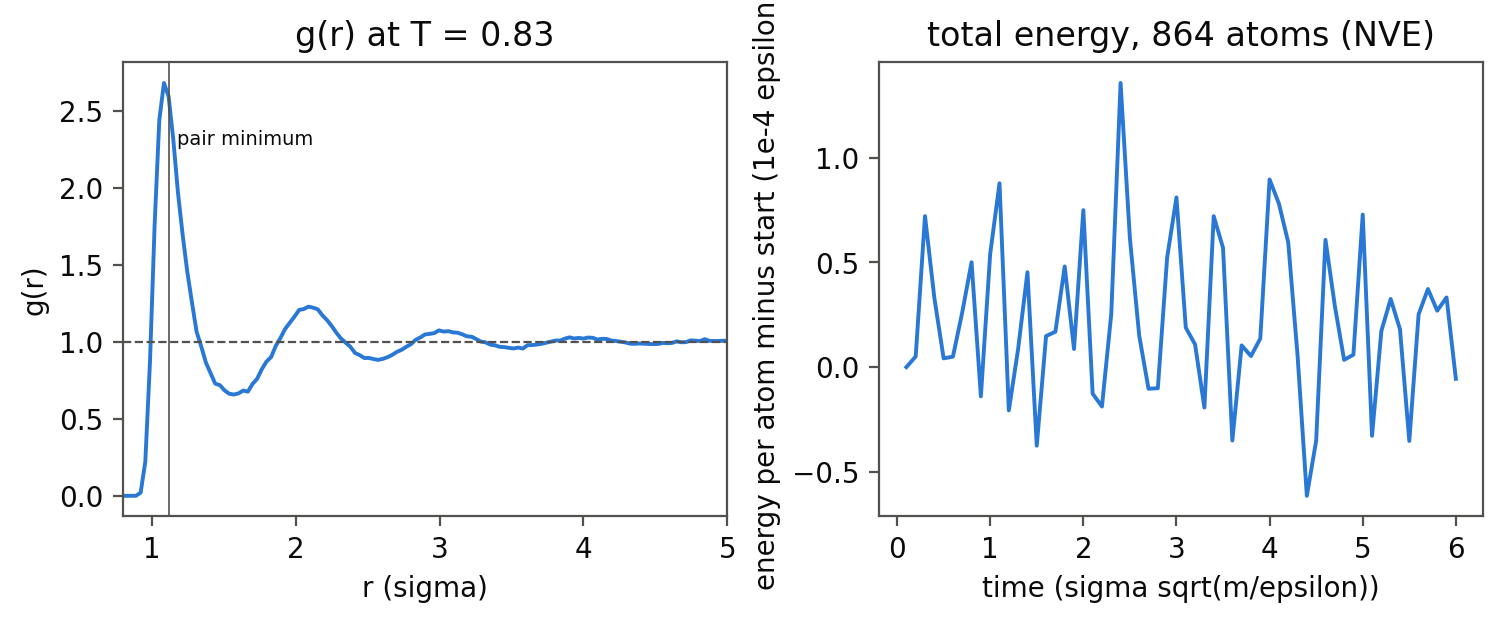
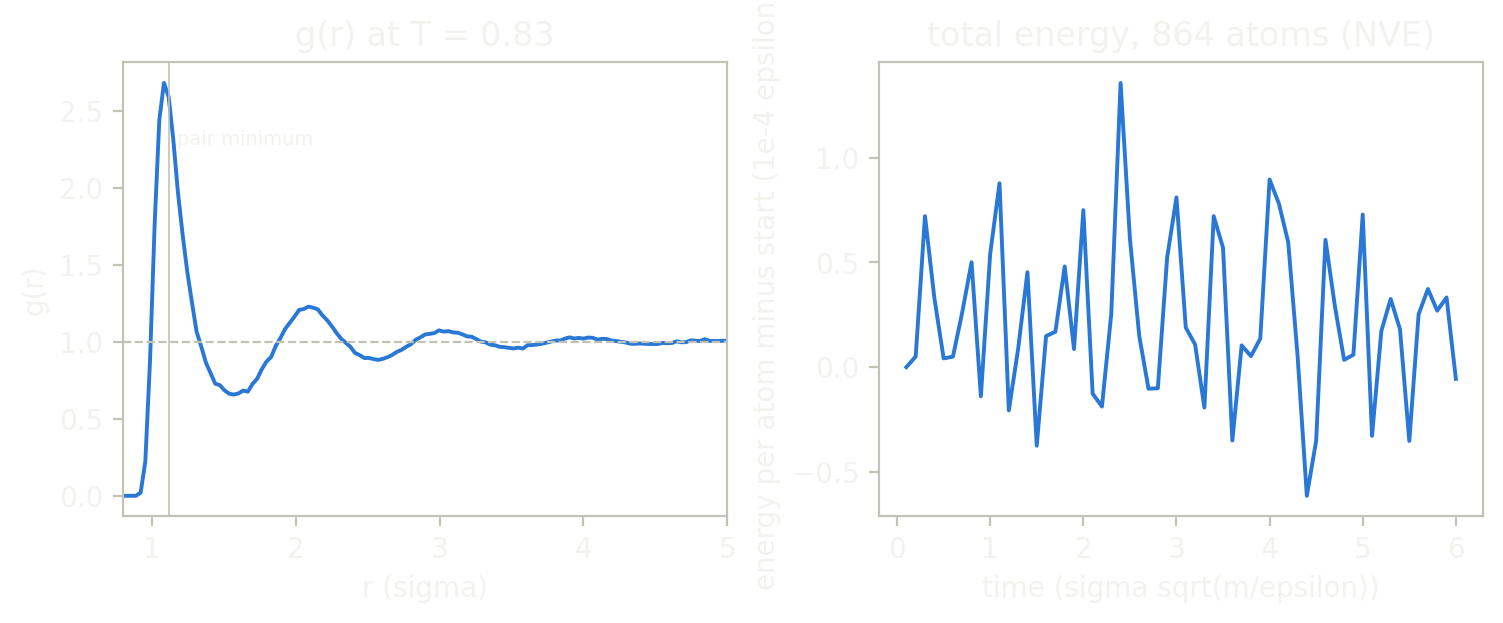

In [10]:
import matplotlib.pyplot as plt

colours = ["#2a78d6", "#eb6834", "#3a9a6a"]
fig, (left, right) = plt.subplots(1, 2, figsize=(7.4, 3.0), constrained_layout=True)
left.plot(r_mid, g_r, lw=1.4, color=colours[0])
left.axhline(1.0, color="#898781", lw=0.8, ls="--")
left.axvline(2 ** (1 / 6), color="#898781", lw=0.6)
left.text(2 ** (1 / 6) + 0.05, g_r.max() * 0.85, "pair minimum", fontsize=7, color="#898781")
left.set_xlim(0.8, 5.0); left.set_xlabel("r (sigma)"); left.set_ylabel("g(r)"); left.set_title(f"g(r) at T = {T_mean:.2f}")
right.plot(times, 1e4 * (total - total[0]), lw=1.4, color=colours[0])
right.set_xlabel("time (sigma sqrt(m/epsilon))"); right.set_ylabel("energy per atom minus start (1e-4 epsilon)"); right.set_title("total energy, 864 atoms (NVE)")
show(fig, f"Two panels. Left: the radial distribution function of {S864.n} Lennard-Jones atoms at density {RHO} and temperature {T_mean:.2f}: a first peak of height {g_r.max():.2f} at r = {peak:.2f}, a trough below 1 near 1.5, smaller shells after, settling to 1. Right: the total energy per atom over {times[-1]:.0f} time units stays within a spread of {total.std():.1e} with no drift; the spread on 500 atoms falls from {fluct[0]:.1e} to {fluct[1]:.1e} to {fluct[2]:.1e} as the time step halves twice.")

## A bigger box, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same kernels, built for 6 912 atoms (`n_side = 12`), run through `eagle.deploy` with their arrays on the device (CuPy), and only the forces come back to the host. The cell list's forces must again match the hand-written ones, now for the gradient on the device, to rounding.

In [11]:
if gpu_available():
    big = make_system(12)
    xb, _ = fcc(12, RHO, jitter=0.1, seed=2)
    order_b, start_b = big.build_cells(xb)
    probe = big.force_run.run(r=xp.asarray(xb[order_b].T.copy()), pos=xp.asarray(xb[order_b]), start=xp.asarray(start_b))
    assert type(probe["f"]).__module__.startswith("cupy"), "the result is a device array: the kernel ran on the GPU"
    got = big.forces_autodiff(xb)
    ref, _, _ = big.forces_analytic(xb)
    gap = np.abs(got - ref).max() / np.abs(ref).max()
    assert gap < 1e-10, gap
    print(f"{big.n} atoms: the gradient's force equals the hand-written one, worst gap {gap:.1e} of the largest force")
else:
    print("no GPU here; the box stays at", S864.n, "atoms")

no GPU here; the box stays at 864 atoms


## The animation

A slab of the liquid, two `sigma` thick, as the atoms move, coloured by their kinetic energy (cool to warm). The positions are the recorded frames of the run above. The helper that writes a looping GIF for a light page and one for a dark page is shared with the other domain pages.

In [12]:
from anim import frame_of, write_anim
from themed_figure import DARK, LIGHT

lo_z, hi_z = 0.0, 2.0
speed2 = np.array([(vf**2).sum(axis=1) for _, vf in frames])
vmax = np.percentile(speed2, 99)


def render(theme, k):
    pal = LIGHT if theme == "light" else DARK
    fig = plt.figure(figsize=(3.4, 3.4), facecolor=pal["bg"])
    ax = fig.add_axes([0.02, 0.02, 0.96, 0.96], facecolor=pal["bg"])
    xf, vf = frames[k]
    slab = (xf[:, 2] >= lo_z) & (xf[:, 2] < hi_z)
    ax.scatter(xf[slab, 0], xf[slab, 1], s=62, c=speed2[k][slab], cmap="plasma", vmin=0, vmax=vmax, edgecolors=pal["bg"], linewidths=0.4)
    ax.set_xlim(0, S864.box); ax.set_ylim(0, S864.box); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_color(pal["rule"])
    ax.text(0.03, 0.96, f"t = {times[k]:.1f}   T = {temperature[k]:.2f}", transform=ax.transAxes, fontsize=8, color=pal["ink"], va="top")
    return frame_of(fig, pal["bg"])


sizes = {}
for theme in ("light", "dark"):
    sizes.update(write_anim([render(theme, k) for k in range(len(frames))] + [render(theme, len(frames) - 1)] * 4, f"lj_liquid_{theme}", fps=10))
for name, size in sizes.items():
    print(name, f"{size / 1e3:.0f} kB")
assert max(sizes.values()) < 1.5e6

lj_liquid_light.gif 1416 kB
lj_liquid_dark.gif 1378 kB


```{image} ../../_static/anim/lj_liquid_light.gif
:class: only-light narrow
:alt: A square slab of a Lennard-Jones liquid seen from above, about 170 atoms drawn as discs coloured from dark to bright by kinetic energy; the atoms jostle and slowly rearrange while the total energy stays constant.
```
```{image} ../../_static/anim/lj_liquid_dark.gif
:class: only-dark narrow
:alt: A square slab of a Lennard-Jones liquid seen from above, about 170 atoms drawn as discs coloured from dark to bright by kinetic energy; the atoms jostle and slowly rearrange while the total energy stays constant.
```

## What just happened

- `Atom` named the position once; `energy` is one atom's energy with its neighbours, and everything else follows from it: the force is minus its gradient in reverse mode.
- The neighbour search is a keyed sum on sorted keys plus one loop over 27 cells. Its forces matched a brute-force sum over all pairs to rounding, so did the gradient's against the hand-written force, and the forces summed to zero.
- Velocity Verlet kept the total energy: the spread fell about fourfold per halving of `dt`, and the long run showed no drift.
- The pair distances gave `g(r)`, whose energy integral equalled the energy the kernel had summed, and the energy of the liquid agreed with the published value for this state point at the run's mean temperature.

## Try this

Raise the density to `rho = 0.9` (the box side follows, and so does the cell count) and watch the first peak of `g(r)` grow and the next ones separate; the published table has `rho = 0.9` too, at `T = 0.85` and `0.90`. Or add a weak harmonic trap, as its own term in the total, `U = 1/2 sum pair + sum trap`, not inside `energy`'s halved pair sum, with its force `-k x` added to the pair force, and see the energy check stay flat.

## Next

[Control](21_control) takes a cost's gradient with respect to gains in the same way. [Particle binning](08_particle_binning) is the keyed sum on its own.